# Practical 8 ML
## Name: Anushka Patel
## Class: C1_A4_50
### Aim: To implement Support Vector Machine (SVM) algorithm for classification.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score,recall_score,f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("ai4i2020.csv")

In [3]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [4]:
df.tail()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0,0,0,0,0,0


In [5]:
df.shape

(10000, 14)

In [50]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [6]:
df["Type"].unique()

array(['M', 'L', 'H'], dtype=object)

In [ ]:
df.columns

In [7]:
print(df.isnull().sum())

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64


In [40]:
df.duplicated().sum()

np.int64(0)

In [41]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [42]:
df.dtypes

UDI                          int64
Product ID                  object
Type                        object
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

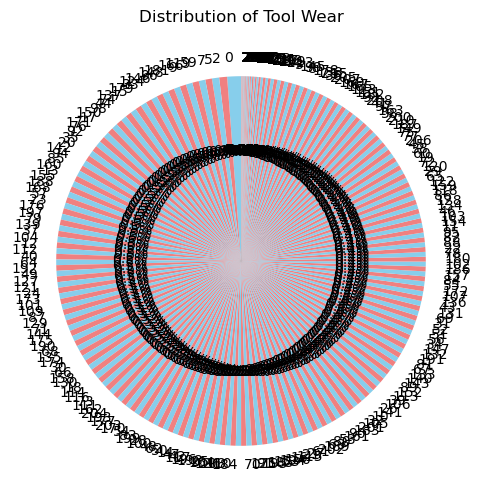

In [47]:
plt.figure(figsize=(6, 6))
df['Tool wear [min]'].value_counts().plot.pie( autopct='%1.1f%%',startangle=90,colors=['skyblue', 'lightcoral'])
plt.title("Distribution of Tool Wear")
plt.ylabel('')
plt.show()

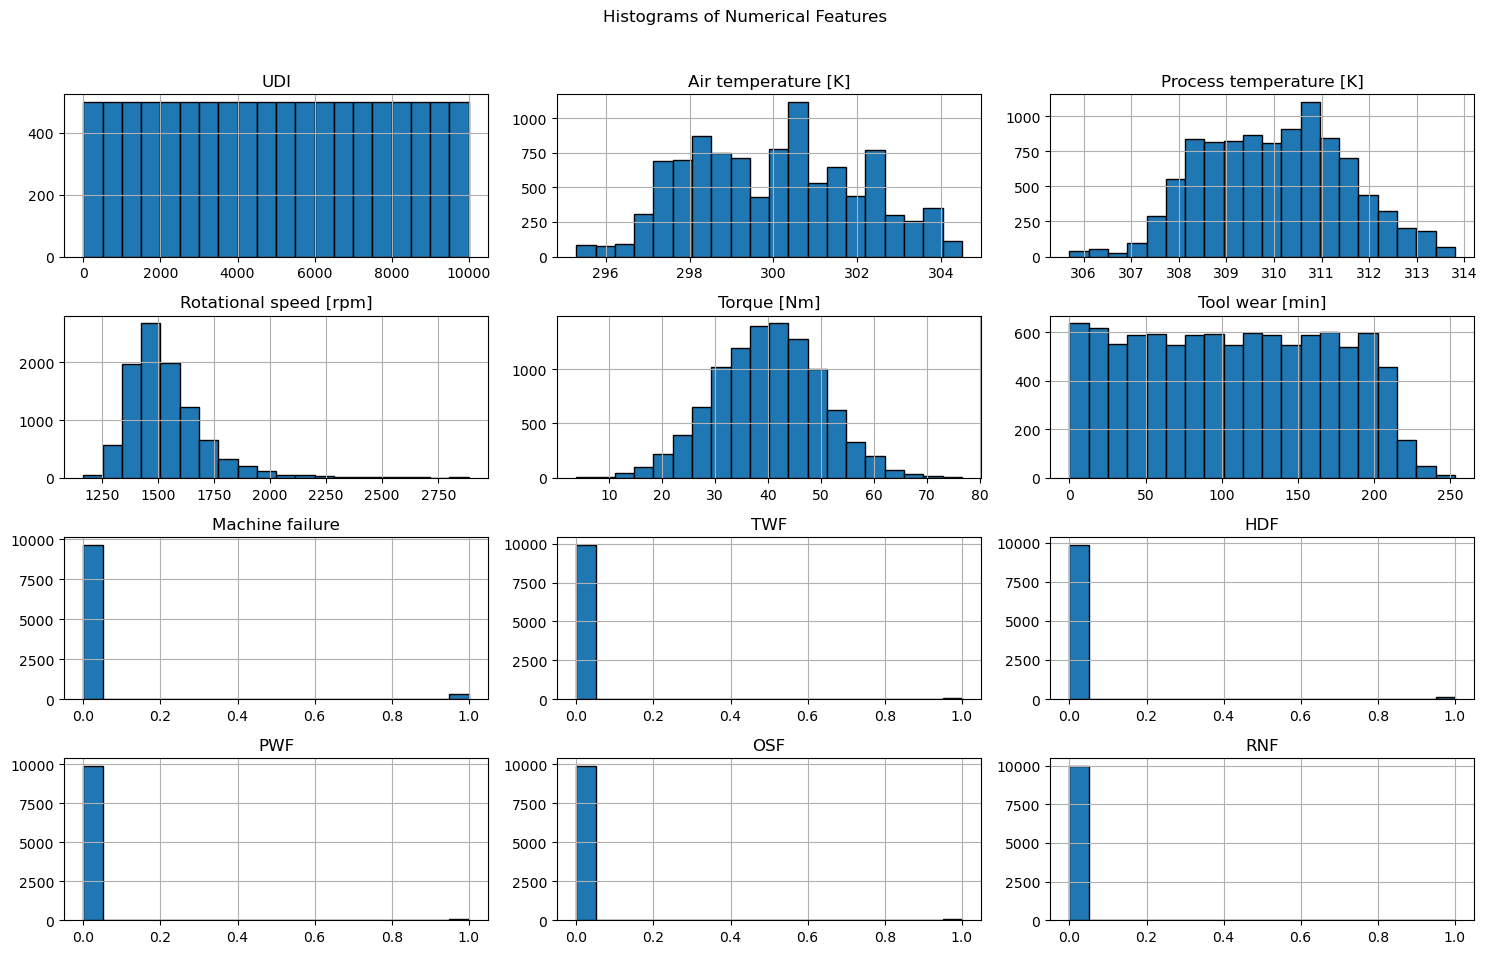

In [49]:
df.hist(figsize=(15, 10), bins=20, edgecolor='black')

plt.suptitle("Histograms of Numerical Features")
plt.tight_layout(rect=[0, 0.03, 1, 0.96])
plt.show()

## OR

In [8]:
X = df[
    [
        "Type",
        "Air temperature [K]",
        "Process temperature [K]",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]"
    ]
]

print(X.head())

  Type  Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  \
0    M                298.1                    308.6                    1551   
1    L                298.2                    308.7                    1408   
2    L                298.1                    308.5                    1498   
3    L                298.2                    308.6                    1433   
4    L                298.2                    308.7                    1408   

   Torque [Nm]  Tool wear [min]  
0         42.8                0  
1         46.3                3  
2         49.4                5  
3         39.5                7  
4         40.0                9  


In [9]:
y = df["Machine failure"]

In [10]:
print("Input shape:",X.shape)
print("Output shape:",y.shape)

Input shape: (10000, 6)
Output shape: (10000,)


In [11]:
categorical_features = ["Type"]

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
print("Training samples:",X_train.shape[0])
print("Testing samples: ",X_test.shape[0])

Training samples: 8000
Testing samples:  2000


In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

In [14]:
numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

categorical_features = ["Type"]

In [15]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

## Linear

In [16]:
linear_svm = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC(kernel="linear"))
    ]
)

linear_svm.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('classifier', SVC(kernel='linear'))])

In [17]:
y_pred_linear = linear_svm.predict(X_test)

In [18]:
print(
    classification_report(y_test,y_pred_linear, target_names=["No Failure","Failure"],
                          zero_division=0
                         )
)

              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.98      1932
     Failure       0.00      0.00      0.00        68

    accuracy                           0.97      2000
   macro avg       0.48      0.50      0.49      2000
weighted avg       0.93      0.97      0.95      2000



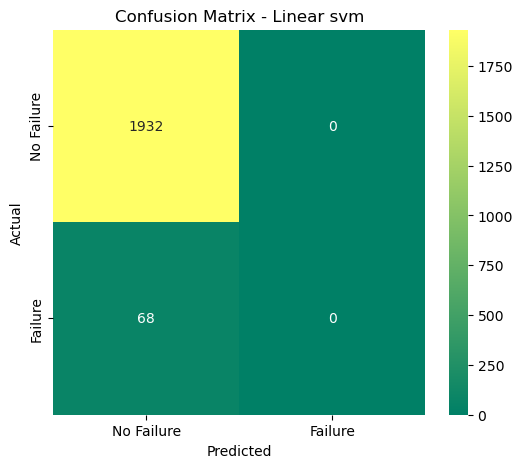

In [19]:
cm_linear = confusion_matrix(y_test, y_pred_linear)

plt.figure(figsize =(6,5))

sns.heatmap(cm_linear,annot=True,fmt="d",cmap="summer",
            xticklabels=["No Failure","Failure"],
            yticklabels=["No Failure","Failure"]
           )
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Linear svm")
plt.show()

In [20]:
accuracy_linear = accuracy_score(y_test, y_pred_linear)

precision_linear = precision_score(y_test, y_pred_linear, zero_division=0)

recall_linear = recall_score(y_test, y_pred_linear, zero_division=0)

f1_linear = f1_score(y_test, y_pred_linear, zero_division=0)

print("Accuracy :", accuracy_linear)
print("Precison :", precision_linear)
print("Recall score:", recall_linear)
print("F1 Score :", f1_linear)

Accuracy : 0.966
Precison : 0.0
Recall score: 0.0
F1 Score : 0.0


## RBF

In [21]:
rbf_svm = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC(kernel="rbf"))
    ]
)

rbf_svm.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('classifier', SVC())])

In [22]:
y_pred_rbf = rbf_svm.predict(X_test)

In [23]:
accuracy_rbf = accuracy_score(y_test, y_pred_rbf)

precision_rbf = precision_score(y_test, y_pred_rbf, zero_division=0)

recall_rbf = recall_score(y_test, y_pred_rbf, zero_division=0)

f1_rbf = f1_score (y_test,y_pred_rbf, zero_division=0)

print("Accuracy :", accuracy_rbf)
print("Precison :", precision_rbf)
print("Recall score:", recall_rbf)
print("F1 Score :", f1_rbf)

Accuracy : 0.972
Precison : 0.875
Recall score: 0.20588235294117646
F1 Score : 0.3333333333333333


# KERNAL POLYNOMIAL

In [24]:
poly_svm = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC(kernel="poly"))
    ]
)

poly_svm.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('classifier', SVC(kernel='poly'))])

In [25]:
y_pred_poly = poly_svm.predict(X_test)

In [26]:
accuracy_poly = accuracy_score(y_test, y_pred_rbf)

precision_poly = precision_score(y_test, y_pred_rbf, zero_division=0)

recall_poly = recall_score(y_test, y_pred_rbf, zero_division=0)

f1_poly = f1_score (y_test,y_pred_rbf, zero_division=0)

print("Accuracy :", accuracy_poly)
print("Precison :", precision_poly)
print("Recall score:", recall_poly)
print("F1 Score :", f1_poly)

Accuracy : 0.972
Precison : 0.875
Recall score: 0.20588235294117646
F1 Score : 0.3333333333333333


## Sigmoid

In [27]:
sigmoid_svm = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC(kernel="sigmoid"))
    ]
)

sigmoid_svm.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('classifier', SVC(kernel='sigmoid'))])

In [28]:
y_pred_sigmoid = sigmoid_svm.predict(X_test)

In [29]:
accuracy_sigmoid = accuracy_score(y_test, y_pred_rbf)

precision_sigmoid = precision_score(y_test, y_pred_rbf, zero_division=0)

recall_sigmoid= recall_score(y_test, y_pred_rbf, zero_division=0)

f1_sigmoid = f1_score (y_test,y_pred_rbf, zero_division=0)

print("Accuracy :", accuracy_sigmoid)
print("Precison :", precision_sigmoid)
print("Recall score:", recall_sigmoid)
print("F1 Score :", f1_sigmoid)

Accuracy : 0.972
Precison : 0.875
Recall score: 0.20588235294117646
F1 Score : 0.3333333333333333


In [30]:
comparison=pd.DataFrame({
    "Kernel":["Linerar","RBF","poly","sigmoid"],
    "Accuracy":[accuracy_linear,accuracy_rbf,accuracy_poly,accuracy_sigmoid],
    "Precison":[precision_linear,precision_rbf,recall_poly,recall_sigmoid],
    "Recall":[recall_linear,recall_rbf,recall_poly,recall_sigmoid],
    "F1 Score":[f1_linear,f1_rbf,f1_poly,f1_sigmoid]})

comparison

,Kernel,Accuracy,Precison,Recall,F1 Score
0,Linerar,0.966,0.000000,0.000000,0.000000
1,RBF,0.972,0.875000,0.205882,0.333333
2,poly,0.972,0.205882,0.205882,0.333333
3,sigmoid,0.972,0.205882,0.205882,0.333333


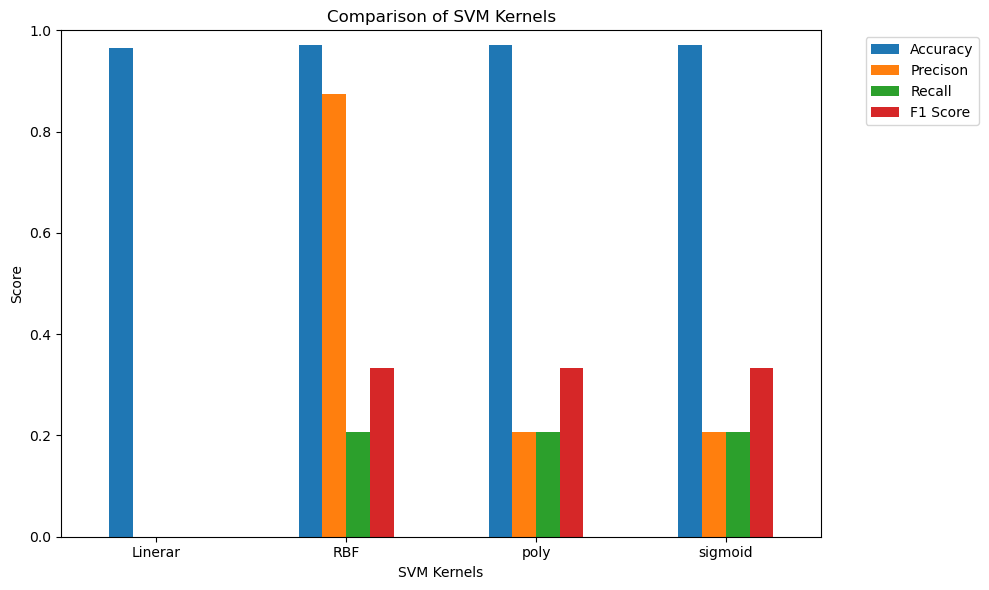

In [31]:
comparison_plot = comparison.set_index("Kernel")

comparison_plot.plot(kind="bar", figsize=(10, 6))

plt.title("Comparison of SVM Kernels")
plt.xlabel("SVM Kernels")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [32]:
from sklearn.pipeline import Pipeline
pipeline = Pipeline(steps = [("preprocessor",preprocessor),("classifier",SVC())])

In [33]:
param_grid = [
    {
        "classifier__kernel": ["linear"],"classifier__C": [0.1, 1, 10, 100]
    },
    {
        "classifier__kernel": ["rbf"],"classifier__C": [0.1, 1, 10, 100],"classifier__gamma": ["scale", 0.01, 0.1, 1]
    }
]

In [34]:
from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

In [35]:
grid_search.fit(X_train, y_train)

print("GridSearchCV completed")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
GridSearchCV completed


In [36]:
print("Best Parameters:", grid_search.best_params_)
print("Best F1 Score:", grid_search.best_score_)

Best Parameters: {'classifier__C': 100, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}
Best F1 Score: 0.7080372186703207


In [37]:
print("Best Cross_Validation F1 Score:", grid_search.best_score_)

Best Cross_Validation F1 Score: 0.7080372186703207


In [38]:
best_model = grid_search.best_estimator_

y_pred_tuned = best_model.predict(X_test)

In [39]:
accuracy_tuned = accuracy_score(y_test,y_pred_tuned)

precision_tuned = precision_score(y_test,y_pred_tuned,zero_division=0)

recall_tuned = recall_score(y_test,y_pred_tuned, zero_division=0)

f1_tuned = f1_score(y_test,y_pred_tuned,zero_division=0)

print("Tuned SVM Results")

print("Accuracy:",accuracy_tuned)
print("Precision:",precision_tuned)
print("Recall:",recall_tuned)
print("F1 Score:",f1_tuned)

Tuned SVM Results
Accuracy: 0.98
Precision: 0.7592592592592593
Recall: 0.6029411764705882
F1 Score: 0.6721311475409836
